# RANDOM FOREST - GINI (100 POHON)

### Deskripsi Teori & Varian:
* **Algoritma**: Random Forest (Ensemble Learning)
* **Varian**: Gini Impurity (100 Pohon)
* **Konsep**: Random Forest membangun banyak *Decision Tree* secara acak dan menggabungkan hasilnya (voting). Varian ini menggunakan kriteria standar **Gini Impurity** untuk mengukur seberapa "murni" sebuah cabang pohon (seberapa banyak data yang salah klasifikasi jika ditebak secara acak). Jumlah pohon yang digunakan adalah 100.

In [1]:
import time
import tracemalloc
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# 1. Load Data
df_hoaks = pd.read_csv('../data/komdigi_hoaks.csv')
df_valid = pd.read_csv('../web/uploads/berita_valid_terbaru.csv')

# 2. Cleaning Text
def clean_text(text):
    if not isinstance(text, str): return ''
    text = re.sub(r'\[(HOAKS|DISINFORMASI|MISINFORMASI|KLARIFIKASI|SALAH|FALSE)\]', '', text, flags=re.IGNORECASE)
    text = re.sub(r'\((HOAKS|DISINFORMASI|MISINFORMASI|KLARIFIKASI|SALAH|FALSE)\)', '', text, flags=re.IGNORECASE)
    text = re.sub(r'https?:\/\/\S+|www\.\S+', '', text)
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    return re.sub(r'\s+', ' ', text.lower()).strip()

df_hoaks['teks_bersih'] = (df_hoaks['title'].fillna('') + ' ' + df_hoaks['excerpt'].fillna('')).apply(clean_text)
df_valid['teks_bersih'] = (df_valid['title'].fillna('') + ' ' + df_valid['excerpt'].fillna('')).apply(clean_text)

df_hoaks['label'] = 1
df_valid['label'] = 0

# 3. Balancing Data
df_hoaks_sampel = df_hoaks.sample(n=len(df_valid), random_state=42)
df_all = pd.concat([df_hoaks_sampel, df_valid], ignore_index=True)
df_all = df_all[df_all['teks_bersih'].str.len() > 10].reset_index(drop=True)

# 4. Split & TF-IDF
X_train, X_test, y_train, y_test = train_test_split(
    df_all['teks_bersih'], df_all['label'], test_size=0.2, random_state=42, stratify=df_all['label']
)
tfidf = TfidfVectorizer(max_features=1500, ngram_range=(1, 2))
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)

print("Preprocessing Selesai!")

Preprocessing Selesai!


In [2]:
tracemalloc.start()
waktu_mulai = time.time()

# Model Random Forest - Gini (100 Pohon)
model = RandomForestClassifier(n_estimators=100, criterion='gini', max_depth=None, random_state=42)
model.fit(X_train_vec, y_train)
y_pred = model.predict(X_test_vec)

waktu_eksekusi = time.time() - waktu_mulai
current_mem, peak_mem = tracemalloc.get_traced_memory()
tracemalloc.stop()
memori_mb = peak_mem / (1024 * 1024)

acc = accuracy_score(y_test, y_pred)
prec_macro = precision_score(y_test, y_pred, average='macro', zero_division=0)
rec_macro = recall_score(y_test, y_pred, average='macro', zero_division=0)
f1_macro = f1_score(y_test, y_pred, average='macro', zero_division=0)
f1_weighted = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print("=============================================")
print("HASIL PENGUJIAN: RANDOM FOREST - GINI (100 POHON)")
print("=============================================")
print(f"1. Algoritma        : Random Forest")
print(f"2. Metrik Jarak     : Gini Impurity (100 Pohon)")
print(f"3. Akurasi          : {acc:.4f}")
print(f"4. Precision (Macro): {prec_macro:.4f}")
print(f"5. Recall (Macro)   : {rec_macro:.4f}")
print(f"6. F1-Score (Macro) : {f1_macro:.4f}")
print(f"7. F1-Score (Weighted): {f1_weighted:.4f}")
print(f"8. Waktu Eksekusi   : {waktu_eksekusi:.4f} detik")
print(f"9. Penggunaan Memori: {memori_mb:.2f} MB")
print("=============================================\n")

print("Laporan Klasifikasi Detail:")
print(classification_report(y_test, y_pred, target_names=['Valid (0)', 'Hoaks (1)'], zero_division=0))

HASIL PENGUJIAN: RANDOM FOREST - GINI (100 POHON)
1. Algoritma        : Random Forest
2. Metrik Jarak     : Gini Impurity (100 Pohon)
3. Akurasi          : 0.9133
4. Precision (Macro): 0.9152
5. Recall (Macro)   : 0.9133
6. F1-Score (Macro) : 0.9132
7. F1-Score (Weighted): 0.9132
8. Waktu Eksekusi   : 0.9907 detik
9. Penggunaan Memori: 0.40 MB

Laporan Klasifikasi Detail:
              precision    recall  f1-score   support

   Valid (0)       0.94      0.88      0.91       150
   Hoaks (1)       0.89      0.95      0.92       150

    accuracy                           0.91       300
   macro avg       0.92      0.91      0.91       300
weighted avg       0.92      0.91      0.91       300



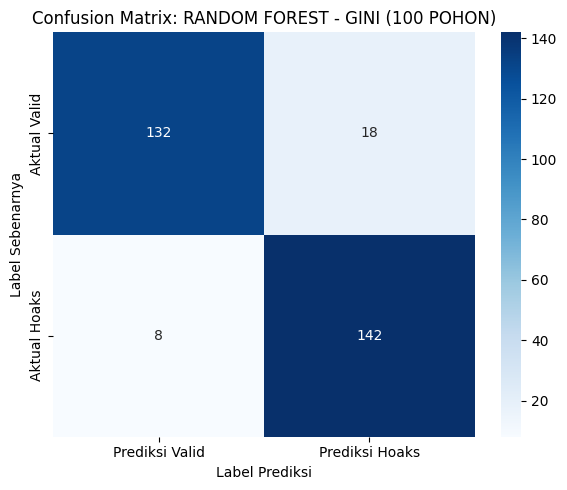

In [3]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Prediksi Valid', 'Prediksi Hoaks'],
            yticklabels=['Aktual Valid', 'Aktual Hoaks'])
plt.title('Confusion Matrix: RANDOM FOREST - GINI (100 POHON)')
plt.ylabel('Label Sebenarnya')
plt.xlabel('Label Prediksi')
plt.tight_layout()
plt.show()

### Pembahasan Akademis: Random Forest (Gini Impurity - 100 Pohon)

1. **Analisis Performa & Akurasi**:
   * Model Random Forest dengan kriteria Gini berhasil mencetak akurasi sebesar **91.33%** dengan F1-Score 0.9132. Ini adalah salah satu performa terbaik sejauh ini, bahkan sedikit mengungguli Logistic Regression (L2).
   * Dari Confusion Matrix, model ini sangat luar biasa dalam mendeteksi berita Hoaks: dari 150 data hoaks, **142 berhasil ditebak dengan benar** (hanya 8 yang lolos menjadi Valid). Ini membuktikan bahwa pola non-linear dari kombinasi kata-kata hoaks berhasil ditangkap dengan sangat baik oleh kumpulan pohon keputusan ini.

2. **Kekuatan Gini Impurity & Ensemble Learning**:
   * Berbeda dengan Logistic Regression yang mencari satu garis pemisah linear, Random Forest membangun 100 pohon keputusan yang masing-masing melihat fitur (kata) secara acak. 
   * Kriteria Gini Impurity sangat efektif dalam mengukur seberapa cepat sebuah kata dapat memisahkan kelas Hoaks dan Valid. Dengan menggabungkan "voting" dari 100 pohon, model menjadi sangat kebal terhadap *noise* (kata-kata yang tidak relevan) dan outlier.

3. **Trade-off Kecepatan**:
   * Waktu eksekusi mencapai **0.9907 detik**, jauh lebih lambat dibanding Logistic Regression (~0.02 detik). Hal ini sangat wajar karena Random Forest harus melatih 100 pohon secara bersamaan. Namun, dengan akurasi 91.33% dan memori yang tetap sangat kecil (0.40 MB), *trade-off* waktu ini sangat sepadan untuk mendapatkan model yang lebih tangguh.